# Tutorial: Run FIPpy on a HYDRAD Output Folder

This notebook shows the minimal public workflow for using this repository with your own HYDRAD output. It reads one HYDRAD strand, runs the Alfven-wave and FIP-bias post-processing pipeline, and recreates representative paper-style plots from the returned `output_data` dictionary.

The full paper workflow notebook, `main_chianti.ipynb`, is intentionally not included because it contains local paths and generated paper products.

## 1. Setup

Install the dependencies from `requirements.txt`, then edit the parameters below. `HYDRAD_DIR` must point to a HYDRAD output folder that `pydrad` can parse.

The processing function writes a derived pickle and diagnostic figures under the repository `results/` directory. Those outputs are ignored by Git.

In [1]:
from pathlib import Path
import sys

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np

REPO_ROOT = Path.cwd().resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from loop.reader import HydradReader
from main_fip_bias_batch import process_hydrad_data

plt.rcParams.update({
    "figure.figsize": (8, 5),
    "axes.grid": True,
    "grid.alpha": 0.25,
})

In [19]:
# Edit these values for your HYDRAD run.
HYDRAD_DIR = Path('/Volumes/Crucial X9/Python_Script/fip_bias_hydrad/hydards/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step')
STRAND_NUM = 0

FREQUENCY = 0.198 * u.s**-1
AMPLITUDE = 0.3 * u.km / u.s
ACOUSTIC_FLUX = 1e8 * u.erg / u.cm**2 / u.s
V_ADD = 0.0 * u.km / u.s

if not HYDRAD_DIR.exists():
    raise FileNotFoundError(
        f"Set HYDRAD_DIR to an existing HYDRAD output folder before running the tutorial: {HYDRAD_DIR}"
    )

## 2. Inspect One HYDRAD Strand

`HydradReader` is a thin wrapper around `pydrad.parse.parse.Strand`. This quick check confirms that the folder and strand number are valid before running the full FIPpy pipeline.

In [20]:
hydrad_strand = HydradReader(str(HYDRAD_DIR), strand_num=STRAND_NUM).read_strand()
print(type(hydrad_strand))

for name in ["time", "coordinate", "electron_density", "electron_temperature"]:
    if hasattr(hydrad_strand, name):
        value = getattr(hydrad_strand, name)
        try:
            print(f"{name}: shape={np.shape(value)}")
        except Exception:
            print(f"{name}: {type(value)}")

<class 'pydrad.parse.parse.Profile'>
time: shape=()
coordinate: shape=(379,)
electron_density: shape=(379,)
electron_temperature: shape=(379,)


## 3. Run The FIPpy Post-Processing Pipeline

This cell solves the wave equations and calculates the FIP-bias quantities for the selected strand. It may take several minutes depending on the HYDRAD output size and machine.

The second path-like argument is kept for compatibility with the original research driver; the current implementation derives the actual results directory internally.

In [21]:
output_data = process_hydrad_data(
    input_file=str(HYDRAD_DIR),
    frequency=FREQUENCY,
    amplitude=AMPLITUDE,
    output_dir=str(HYDRAD_DIR),
    strand_num=STRAND_NUM,
    acoustic_flux=ACOUSTIC_FLUX,
    v_add=V_ADD,
)

print("Available output_data keys:")
for key in sorted(output_data):
    print(f"- {key}")

Loading from pydrad profile
Solving ODE 
Function evaluations: 7580
Number of steps: 3103
ODE solved
Element: Ca, Atomic Number: 20, Mass Number: 40.078
Element: Mg, Atomic Number: 12, Mass Number: 24.304
Element: Fe, Atomic Number: 26, Mass Number: 55.845
Element: Si, Atomic Number: 14, Mass Number: 28.084
Element: S, Atomic Number: 16, Mass Number: 32.059
Element: C, Atomic Number: 6, Mass Number: 12.0096
Element: N, Atomic Number: 7, Mass Number: 14.0064
Element: O, Atomic Number: 8, Mass Number: 15.999
Element: Ne, Atomic Number: 10, Mass Number: 20.1797
Element: Ar, Atomic Number: 18, Mass Number: 39.948
Saved FIP bias vs height plot for 0.198_0.30_0: /Volumes/Crucial X9/Python_Script/fip_bias_hydrad/hydards/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step/v_0.1980_A_0.30_F_1.0e08/images/fip_bias_vs_height_multi_0.198_0.30_0.png
Available output_data keys:
- B
- I_minus
- I_plus
- T
- VA_s
- acceleration_cm_s2
- acoustic_flux
- amplitude
- collision_components_d

## 4. Plot Helpers

The functions below use only `output_data`, so you can rerun the plotting cells later from a saved result dictionary if needed.

In [22]:
def quantity_values(values, unit=None):
    """Return a NumPy array, converting Astropy quantities when present."""
    if hasattr(values, "to") and unit is not None:
        return np.asarray(values.to(unit).value)
    if hasattr(values, "value"):
        return np.asarray(values.value)
    return np.asarray(values)


# Outer 6 Mm of each leg, the chromospheric window used for the paper figures.
FOOTPOINT_DEPTH_MM = 6.0


def loop_distance_mm(data):
    return quantity_values(data["s_values"], u.Mm)


def loop_length_mm(data):
    if "loop_length" in data:
        return float(np.asarray(quantity_values(data["loop_length"], u.Mm)))
    return float(np.nanmax(loop_distance_mm(data)))


def footpoint_axes(fig_height=4.6):
    """Left and right footpoints, both measured upward from that footpoint."""
    fig, axes = plt.subplots(1, 2, figsize=(11, fig_height), sharey=True)
    for ax, title in zip(axes, ("Left footpoint", "Right footpoint")):
        ax.set_xscale("log")
        ax.set_xlabel("Height above footpoint (Mm)")
        ax.set_title(title)
    return fig, axes


def heights_above_footpoint(s_mm, length):
    s_mm = np.asarray(s_mm, dtype=float)
    return s_mm, length - s_mm


def footpoint_slice(height_mm, *columns, depth_mm=FOOTPOINT_DEPTH_MM):
    height_mm = np.asarray(height_mm, dtype=float)
    keep = (height_mm > 0) & (height_mm <= depth_mm) & np.isfinite(height_mm)
    ordered = np.argsort(height_mm[keep])
    sliced = [height_mm[keep][ordered]]
    for column in columns:
        values = np.asarray(column)[keep][ordered]
        sliced.append(values)
    return sliced


def plot_loop_atmosphere(data):
    s_mm = loop_distance_mm(data)
    length = loop_length_mm(data)
    temperature = quantity_values(data["T"], u.K)
    density = quantity_values(data["ne"], u.cm**-3)
    left_height, right_height = heights_above_footpoint(s_mm, length)

    fig, axes = footpoint_axes()
    for ax, height in zip(axes, (left_height, right_height)):
        h, n_e, t = footpoint_slice(height, density, temperature)
        ax_temperature = ax.twinx()
        density_line = ax.semilogy(h, n_e, color="tab:blue", label="Electron density")
        temperature_line = ax_temperature.semilogy(h, t, color="tab:red", label="Temperature")
        ax.set_ylabel("Electron density (cm$^{-3}$)", color="tab:blue")
        ax_temperature.set_ylabel("Temperature (K)", color="tab:red")
        ax.tick_params(axis="y", labelcolor="tab:blue")
        ax_temperature.tick_params(axis="y", labelcolor="tab:red")
        lines = density_line + temperature_line
        ax.legend(lines, [line.get_label() for line in lines], loc="best")
    fig.suptitle("HYDRAD atmosphere used by FIPpy")
    fig.tight_layout()
    return fig


def plot_ponderomotive_acceleration(data):
    s_mm = loop_distance_mm(data)
    length = loop_length_mm(data)
    acceleration = quantity_values(data["ponderomotive_acceleration"], u.cm / u.s**2)
    left_height, right_height = heights_above_footpoint(s_mm, length)

    fig, axes = footpoint_axes(4.4)
    for ax, height in zip(axes, (left_height, right_height)):
        h, a_p = footpoint_slice(height, acceleration)
        ax.plot(h, a_p, color="black")
        ax.axhline(0.0, color="0.5", linewidth=0.8)
        ax.set_ylabel("Ponderomotive acceleration (cm s$^{-2}$)")
    fig.suptitle("Ponderomotive acceleration along the loop")
    fig.tight_layout()
    return fig


def plot_ionisation_fractions(data, elements=("Ca", "Fe", "Mg", "Si", "O", "Ne", "Ar")):
    s_mm = loop_distance_mm(data)
    length = loop_length_mm(data)
    fractions = data["ionization_fractions"]
    present = [element for element in elements if element in fractions]
    left_height, right_height = heights_above_footpoint(s_mm, length)

    fig, axes = footpoint_axes()
    for ax, height in zip(axes, (left_height, right_height)):
        for element in present:
            h, fraction = footpoint_slice(height, np.clip(fractions[element], 1e-6, 1.0))
            ax.semilogy(h, fraction, label=element)
        ax.set_ylabel("Ionisation fraction")
        ax.set_ylim(1e-4, 1.1)
        ax.legend(ncol=2)
    fig.suptitle("Ionisation fractions used in the fractionation calculation")
    fig.tight_layout()
    return fig


def bias_arrays(data, element, side):
    segment = data["fip_bias_heights"].get(element, {}).get(side)
    if segment is None:
        return None, None
    heights = quantity_values(segment["heights"])
    bias = quantity_values(segment["bias"])
    return heights, bias


def plot_fip_bias_relative_to_oxygen(data, elements=("Ca", "Fe", "Mg", "Si", "S", "Ar", "Ne")):
    length = loop_length_mm(data)
    fig, axes = footpoint_axes()
    for ax, side in zip(axes, ("left", "right")):
        oxygen_height, oxygen_bias = bias_arrays(data, "O", side)
        if oxygen_height is None:
            ax.set_title(f"{side.capitalize()} footpoint: no oxygen data")
            continue
        oxygen_height = np.asarray(oxygen_height, dtype=float)
        if side == "right":
            oxygen_height = length - oxygen_height
        oxygen_order = np.argsort(oxygen_height)
        oxygen_height = oxygen_height[oxygen_order]
        oxygen_bias = np.asarray(oxygen_bias, dtype=float)[oxygen_order]
        for element in elements:
            heights, bias = bias_arrays(data, element, side)
            if heights is None:
                continue
            heights = np.asarray(heights, dtype=float)
            bias = np.asarray(bias, dtype=float)
            if side == "right":
                heights = length - heights
            h, ratio = footpoint_slice(heights, bias / np.interp(heights, oxygen_height, oxygen_bias))
            ax.plot(h, ratio, label=f"{element}/O")
        ax.axhline(1.0, color="0.5", linewidth=0.8)
        ax.set_ylabel("FIP bias normalized to O")
        ax.legend(ncol=2)
    fig.suptitle("FIP bias at the two footpoints")
    fig.tight_layout()
    return fig


## 5. Recreate Representative Paper-Style Plots

These are simplified versions of plots used in the paper workflow: loop atmosphere, ponderomotive acceleration, ionisation fractions, and FIP bias normalized to oxygen.

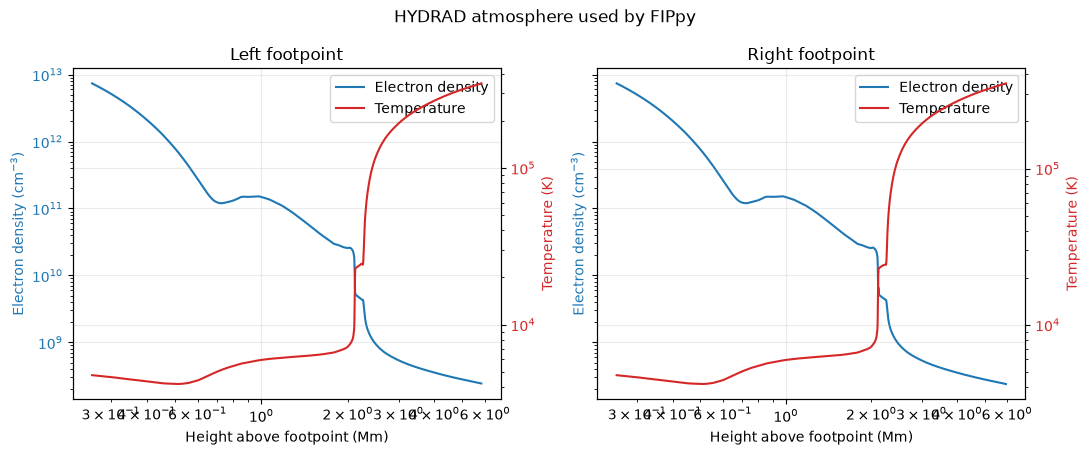

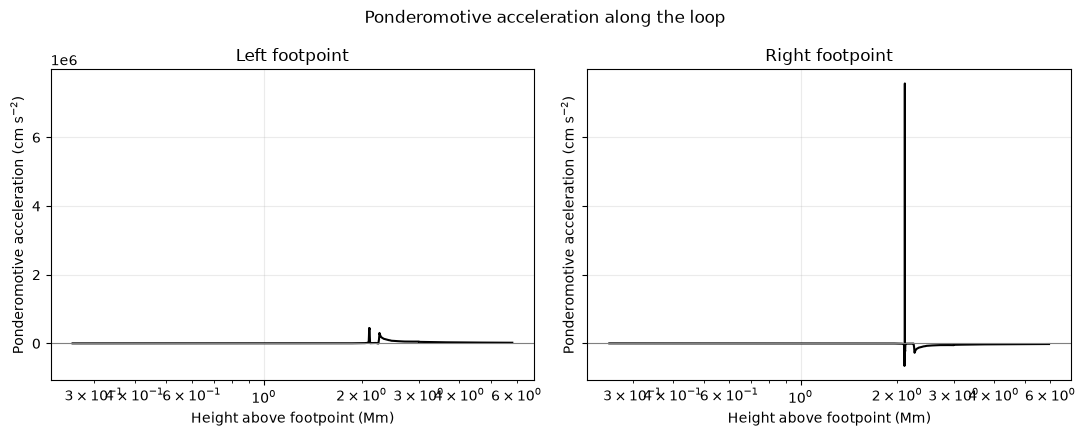

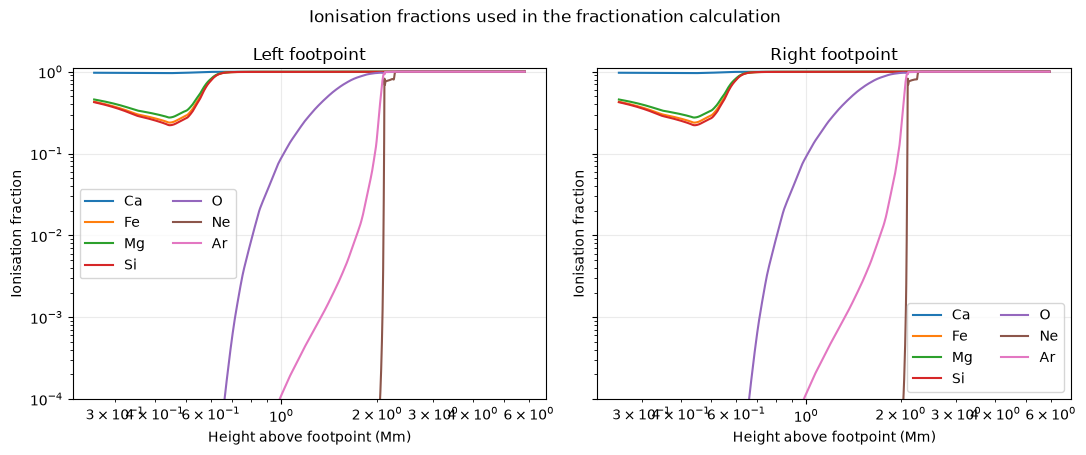

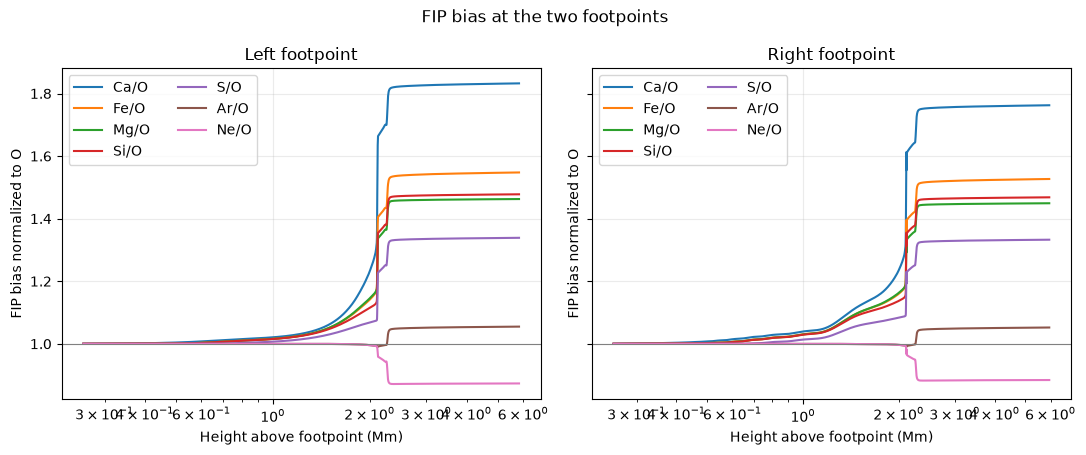

In [23]:
plot_loop_atmosphere(output_data)
plot_ponderomotive_acceleration(output_data)
plot_ionisation_fractions(output_data)
plot_fip_bias_relative_to_oxygen(output_data)
plt.show()

## 6. Optional: Small Parameter Sweep

The paper explores how acoustic flux and additional turbulent velocity affect the predicted FIP bias. The example below runs a small `v_add` sweep. It can be expensive, so reduce or expand the values depending on your machine.

Loading from pydrad profile
Solving ODE 
Function evaluations: 7258
Number of steps: 2991
ODE solved
Element: Ca, Atomic Number: 20, Mass Number: 40.078
Element: Mg, Atomic Number: 12, Mass Number: 24.304
Element: Fe, Atomic Number: 26, Mass Number: 55.845
Element: Si, Atomic Number: 14, Mass Number: 28.084
Element: S, Atomic Number: 16, Mass Number: 32.059
Element: C, Atomic Number: 6, Mass Number: 12.0096
Element: N, Atomic Number: 7, Mass Number: 14.0064
Element: O, Atomic Number: 8, Mass Number: 15.999
Element: Ne, Atomic Number: 10, Mass Number: 20.1797
Element: Ar, Atomic Number: 18, Mass Number: 39.948
Saved FIP bias vs height plot for 0.206_0.15_0: /Volumes/Crucial X9/Python_Script/fip_bias_hydrad/hydards/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step/v_0.2060_A_0.15_F_1.0e07/images/fip_bias_vs_height_multi_0.206_0.15_0.png
Loading from pydrad profile
Solving ODE 


Function evaluations: 7258
Number of steps: 2991
ODE solved
Element: Ca, Atomic Number: 20, Mass Number: 40.078
Element: Mg, Atomic Number: 12, Mass Number: 24.304
Element: Fe, Atomic Number: 26, Mass Number: 55.845
Element: Si, Atomic Number: 14, Mass Number: 28.084
Element: S, Atomic Number: 16, Mass Number: 32.059
Element: C, Atomic Number: 6, Mass Number: 12.0096
Element: N, Atomic Number: 7, Mass Number: 14.0064
Element: O, Atomic Number: 8, Mass Number: 15.999
Element: Ne, Atomic Number: 10, Mass Number: 20.1797
Element: Ar, Atomic Number: 18, Mass Number: 39.948
Saved FIP bias vs height plot for 0.206_0.15_0: /Volumes/Crucial X9/Python_Script/fip_bias_hydrad/hydards/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step/v_0.2060_A_0.15_F_1.0e07/images/fip_bias_vs_height_multi_0.206_0.15_0.png
Loading from pydrad profile
Solving ODE 


Function evaluations: 7258
Number of steps: 2991
ODE solved
Element: Ca, Atomic Number: 20, Mass Number: 40.078
Element: Mg, Atomic Number: 12, Mass Number: 24.304
Element: Fe, Atomic Number: 26, Mass Number: 55.845
Element: Si, Atomic Number: 14, Mass Number: 28.084
Element: S, Atomic Number: 16, Mass Number: 32.059
Element: C, Atomic Number: 6, Mass Number: 12.0096
Element: N, Atomic Number: 7, Mass Number: 14.0064
Element: O, Atomic Number: 8, Mass Number: 15.999
Element: Ne, Atomic Number: 10, Mass Number: 20.1797
Element: Ar, Atomic Number: 18, Mass Number: 39.948
Saved FIP bias vs height plot for 0.206_0.15_0: /Volumes/Crucial X9/Python_Script/fip_bias_hydrad/hydards/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step/v_0.2060_A_0.15_F_1.0e07/images/fip_bias_vs_height_multi_0.206_0.15_0.png


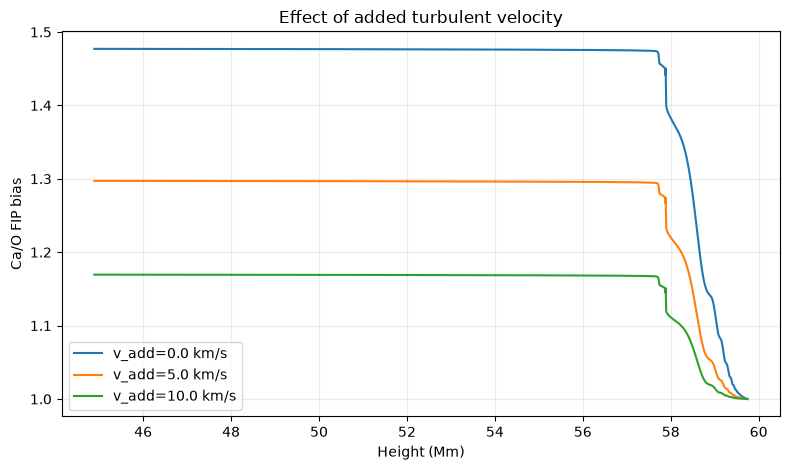

In [13]:
RUN_V_ADD_SWEEP = True
V_ADD_SWEEP = [0.0, 5.0, 10.0] * u.km / u.s

sweep_results = []
if RUN_V_ADD_SWEEP:
    for v_add in V_ADD_SWEEP:
        result = process_hydrad_data(
            input_file=str(HYDRAD_DIR),
            frequency=FREQUENCY,
            amplitude=AMPLITUDE,
            output_dir=str(HYDRAD_DIR),
            strand_num=STRAND_NUM,
            acoustic_flux=ACOUSTIC_FLUX,
            v_add=v_add,
        )
        sweep_results.append((v_add, result))

    fig, ax = plt.subplots(figsize=(8, 4.8))
    for v_add, result in sweep_results:
        oxygen_height, oxygen_bias = bias_arrays(result, "O", "right")
        calcium_height, calcium_bias = bias_arrays(result, "Ca", "right")
        calcium_over_oxygen = calcium_bias / np.interp(calcium_height, oxygen_height, oxygen_bias)
        ax.plot(calcium_height, calcium_over_oxygen, label=f"v_add={v_add.to_value(u.km/u.s):.1f} km/s")

    ax.set_xlabel("Height (Mm)")
    ax.set_ylabel("Ca/O FIP bias")
    ax.set_title("Effect of added turbulent velocity")
    ax.legend()
    fig.tight_layout()
    plt.show()